# <center>🖐️ Практика 6. Распознавание рукописных цифр на PyTorch</center>
### <center>Прикладные технологии ИИ · 120 минут (2 ч.) · Модуль 3</center>

<div style='text-align: center; margin: 20px;'>
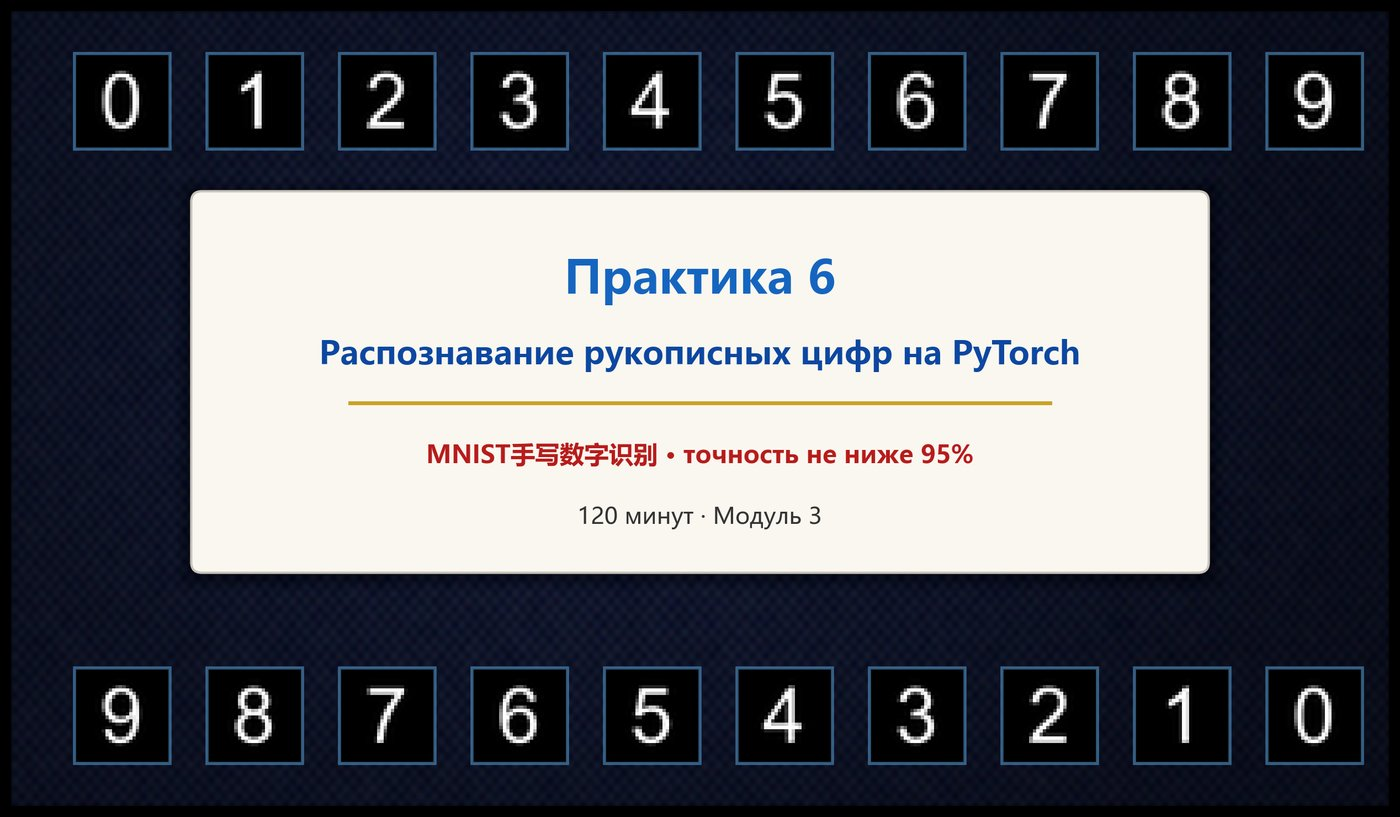
</div>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цель:</b> обучить свёрточную сеть на наборе MNIST и получить точность на тесте <b>не ниже 95 %</b> (требование плана).
</div>

<div style='text-align: center; margin: 20px;'>
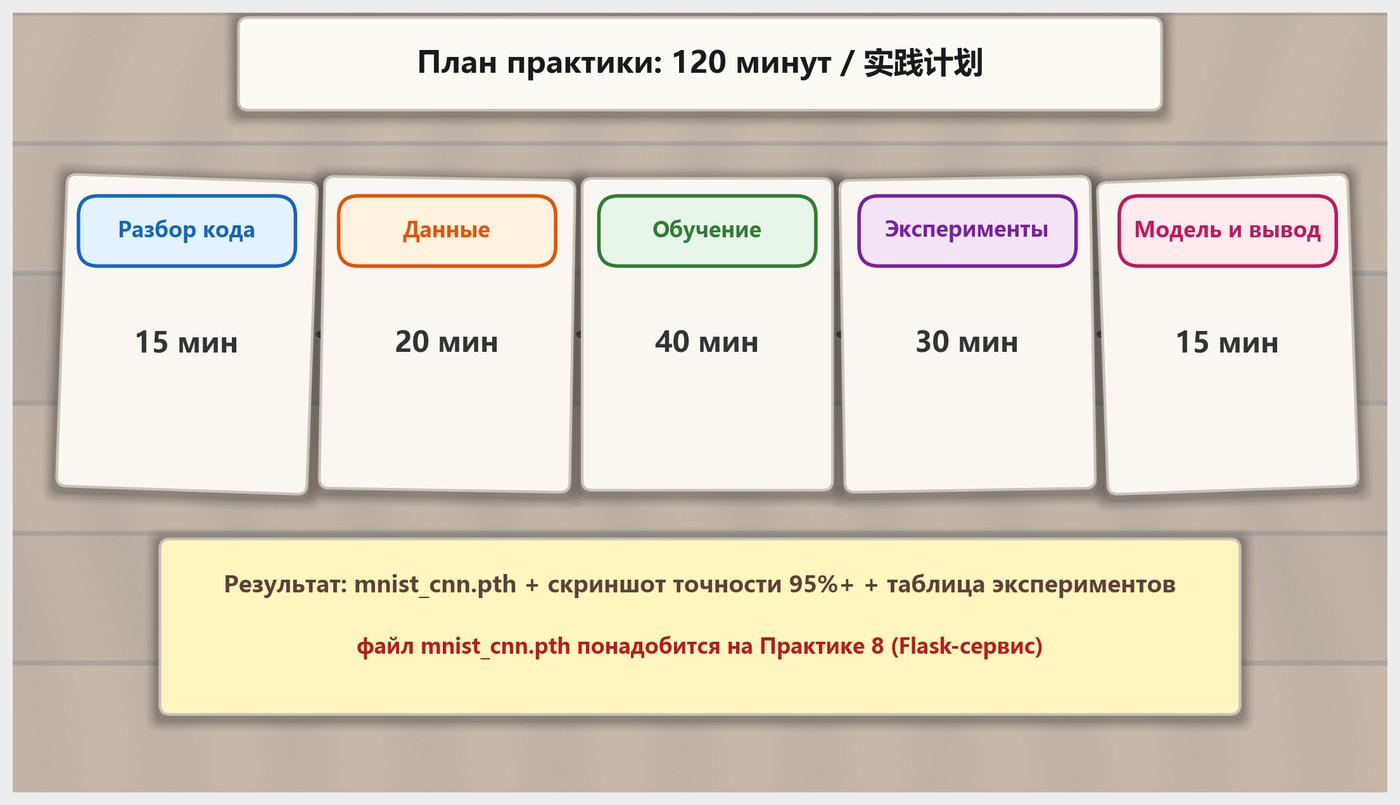
</div>

<center><i>Студент: _______________ · Группа: _______________ · Дата: _______________</i></center>

## 📖 Введение

**MNIST** (Modified National Institute of Standards and Technology) — это классический
учебный набор данных из 70 000 чёрно-белых изображений рукописных цифр (60 000 для
обучения и 10 000 для теста). Каждая картинка имеет размер 28×28 пикселей в оттенках
серого (от 0 до 255) и помечена правильной цифрой от 0 до 9. MNIST стал «hello world»
машинного обучения: на нём проверяют идеи уже тридцать лет, и получить на нём точность
выше 99 % сегодня не составляет труда, но каждая десятая доля процента на дороже предыдущей.

**Почему свёрточная сеть (CNN), а не полносвязная?** Если «развернуть» картинку 28×28
в вектор из 784 чисел и подать его в полносвязную сеть (MLP), модель потеряет
пространственную структуру: она не будет знать, что пиксели (i, j) и (i, j+1) — соседи.
Свёрточная сеть (Convolutional Neural Network, CNN) устроена иначе — она **скользит
небольшим фильтром** по картинке, и каждый фильтр «ищет» свой паттерн: вертикальные
края, горизонтальные штрихи, диагонали, замкнутые петли. Благодаря этому CNN
находит одни и те же признаки в любой части изображения и использует в сотни раз
меньше параметров, чем полносвязная сеть той же выразительности.

**Свёртка (convolution)** — операция, в которой маленькая матрица весов (например,
3×3) проходит по всему изображению, умножается на соответствующий участок и
суммируется в одно число. Результат — карта признаков (feature map), где яркие точки
соответствуют местам, где фильтр «нашёл» свой паттерн.

**Пулинг (pooling)** — уменьшение карты признаков. Чаще всего берут максимум из
каждого окна 2×2 (MaxPool2d): размер карты сокращается вдвое по каждой стороне,
а самая важная информация остаётся. Пулинг делает сеть инвариантной к небольшим
сдвигам и уменьшает число параметров.

**Какие гиперпараметры настраивать в CNN:**
- **Число фильтров** в каждом свёрточном слое (16, 32, 64 — растёт с глубиной);
- **Размер ядра** (kernel size) — обычно 3×3 или 5×5;
- **Шаг (stride)** и **padding** — управляют размером выхода;
- **Размер пулинга** — почти всегда 2×2;
- **Число свёрточных блоков** (depth) — чем глубже, тем сложнее признаки;
- **Размер батча** (batch size) — типичные значения 32, 64, 128;
- **Скорость обучения (learning rate, lr)** — самая важная гиперпеременная;
- **Число эпох** — сколько раз модель видит весь обучающий набор;
- **Оптимизатор** — Adam, SGD с моментом, RMSProp;
- **Dropout / BatchNorm** — регуляризация для борьбы с переобучением.

В этой практике мы соберём простую, но полноценную CNN на PyTorch, обучим её на
MNIST, посмотрим на ошибки и проведём серию экспериментов по подбору гиперпараметров.


In [1]:
# Настройка среды: убираем конфликт MKL/OpenMP, который может убивать ядро на Windows
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'

import numpy as np
import pandas as pd

import matplotlib
try:
    matplotlib.use('module://matplotlib_inline.backend_inline')
except Exception:
    pass
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print('✅ Среда готова')

✅ Среда готова


In [2]:
import torch
torch.set_num_threads(1)
print('PyTorch:', torch.__version__)

PyTorch: 2.14.1+cpu


---
# 🔧 Подготовка: проверка папки с MNIST

Стандартная загрузка MNIST идёт с зарубежных серверов и в Китае часто не работает, поэтому файлы лежат локально: папка `data/MNIST/raw` с четырьмя файлами рядом с тетрадью.

In [3]:
import os
ok = os.path.exists('data/MNIST/raw/train-images-idx3-ubyte')
print('data/MNIST/raw/train-images-idx3-ubyte существует:', ok)
if not ok:
    print('Файлов нет — следующая ячейка скачает их с китайских зеркал (Huawei OBS / Tsinghua).')

data/MNIST/raw/train-images-idx3-ubyte существует: True


<div style='background-color: #FFF3E0; padding: 12px; border-left: 5px solid #E65100;'>
<b>⚠️ Если и зеркала недоступны:</b> скопируйте папку `data/MNIST/raw` с флешки преподавателя либо выполните вариант практики на встроенном наборе `digits` (Практика 5, часть А, точность 96–98 %), а файл модели для Практики 8 получите у преподавателя.
</div>

---
# 📖 Часть 1. Разбор кода (15 мин)

## Архитектура сети

<div style='text-align: center; margin: 20px;'>
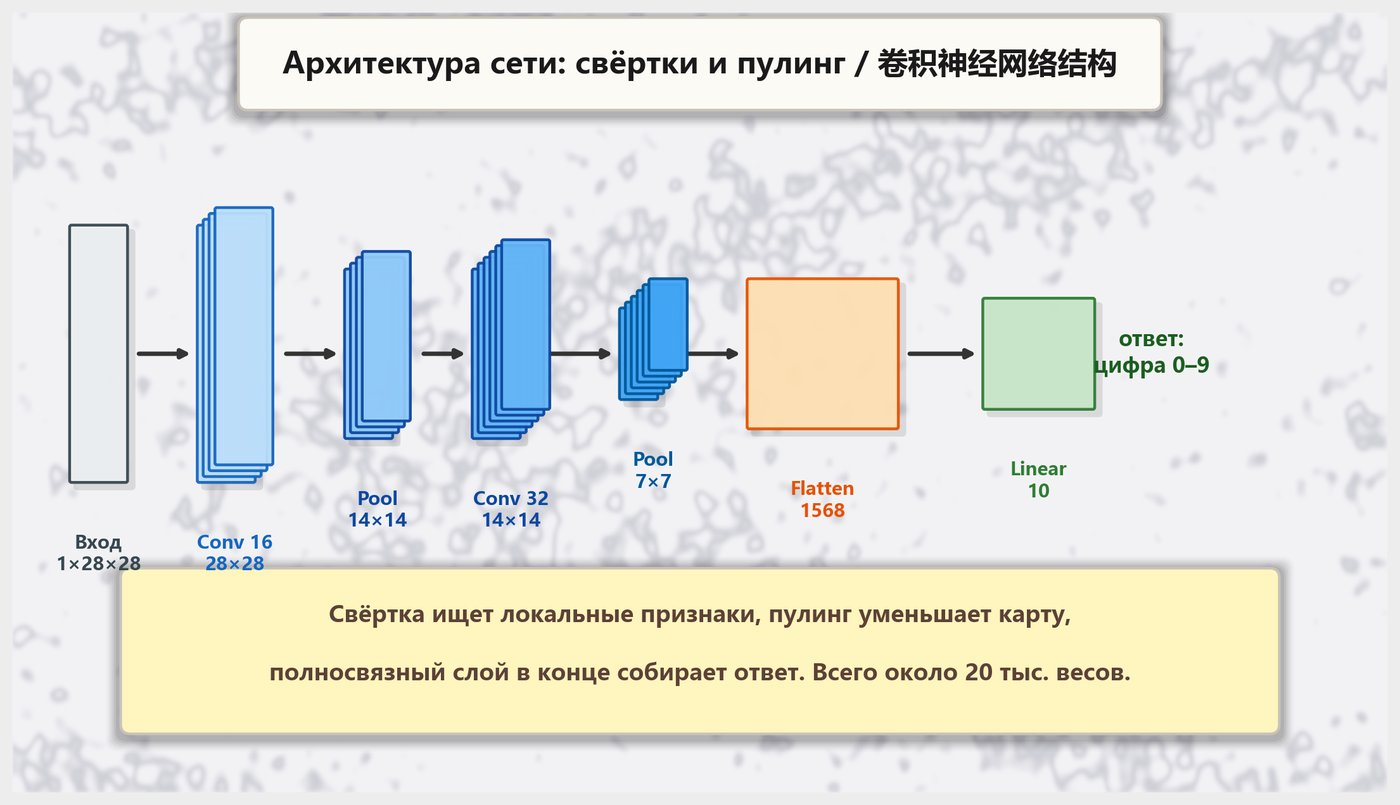
</div>

| Слой | Код | Форма выхода |
|------|-----|--------------|
| Вход | — | 1×28×28 |
| Свёртка 1 | `nn.Conv2d(1, 16, 3, padding=1)` + ReLU | 16×28×28 |
| Пулинг 1 | `nn.MaxPool2d(2)` | 16×14×14 |
| Свёртка 2 | `nn.Conv2d(16, 32, 3, padding=1)` + ReLU | 32×14×14 |
| Пулинг 2 | `nn.MaxPool2d(2)` | 32×7×7 |
| Выпрямление | `nn.Flatten()` | 1568 |
| Полносвязный | `nn.Linear(32 * 7 * 7, 10)` | 10 |

**Почему именно CNN?** Полносвязная сеть для 28×28 потребовала бы миллионы весов и потеряла бы соседство пикселей. Свёртка скользит фильтром по картинке и находит края и штрихи, а пулинг уменьшает карту признаков, оставляя главное.

---
# 🗂️ Часть 2. Загрузка и просмотр данных (20 мин)

<div style='text-align: center; margin: 20px;'>
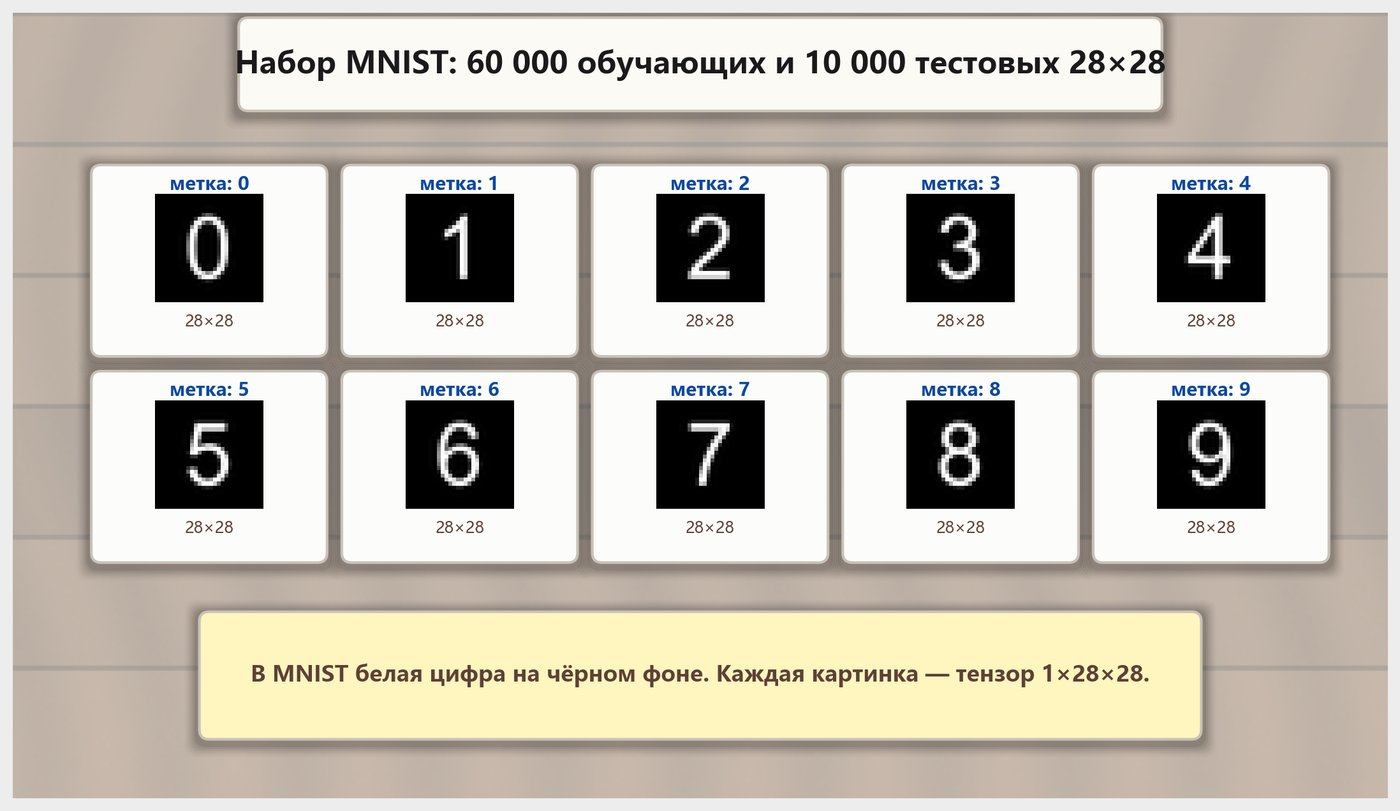
</div>

In [4]:
import gzip
import struct
import urllib.request
import torch
from torch.utils.data import TensorDataset, DataLoader

# ------------------------------------------------------------
# 1. Скачивание и распаковка MNIST с китайских зеркал
# ------------------------------------------------------------
def download_mnist(root='data/MNIST/raw'):
    os.makedirs(root, exist_ok=True)
    huawei_base = 'https://mindspore-website.obs.myhuaweicloud.com/notebook/datasets/mnist/'
    tsinghua_base = 'https://mirrors.tuna.tsinghua.edu.cn/pytorch/data/mnist/'
    files = ['train-images-idx3-ubyte', 'train-labels-idx1-ubyte',
             't10k-images-idx3-ubyte', 't10k-labels-idx1-ubyte']
    for fname in files:
        raw_path = os.path.join(root, fname)
        if os.path.exists(raw_path):
            continue
        downloaded = False
        try:
            print(f'Скачиваю {fname} с Huawei OBS...')
            urllib.request.urlretrieve(huawei_base + fname, raw_path)
            downloaded = True
        except Exception as e:
            print(f'  не получилось: {e}')
        if not downloaded:
            gz_path = raw_path + '.gz'
            try:
                print(f'Скачиваю {fname}.gz с Tsinghua...')
                urllib.request.urlretrieve(tsinghua_base + fname + '.gz', gz_path)
                with gzip.open(gz_path, 'rb') as f_in:
                    data = f_in.read()
                with open(raw_path, 'wb') as f_out:
                    f_out.write(data)
                os.remove(gz_path)
                downloaded = True
            except Exception as e:
                print(f'  не получилось: {e}')
                if os.path.exists(gz_path):
                    os.remove(gz_path)
        if not downloaded:
            raise RuntimeError(f'Не удалось скачать {fname}. Положите файлы вручную в {root}.')
    print('✅ Все четыре файла MNIST на месте.')

# ------------------------------------------------------------
# 2. Чтение idx-файлов в NumPy
# ------------------------------------------------------------
def read_idx_images(path):
    with open(path, 'rb') as f:
        magic, num, rows, cols = struct.unpack('>IIII', f.read(16))
        data = np.frombuffer(f.read(), dtype=np.uint8).reshape(num, rows, cols)
    return data

def read_idx_labels(path):
    with open(path, 'rb') as f:
        magic, num = struct.unpack('>II', f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)
    return labels

# ------------------------------------------------------------
# 3. Загрузка в тензоры и загрузчики (без warning про read-only)
# ------------------------------------------------------------
download_mnist()
X_train = read_idx_images('data/MNIST/raw/train-images-idx3-ubyte')
y_train = read_idx_labels('data/MNIST/raw/train-labels-idx1-ubyte')
X_test  = read_idx_images('data/MNIST/raw/t10k-images-idx3-ubyte')
y_test  = read_idx_labels('data/MNIST/raw/t10k-labels-idx1-ubyte')

X_tr = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1) / 255.0
X_te = torch.tensor(X_test,  dtype=torch.float32).unsqueeze(1) / 255.0
y_tr = torch.tensor(y_train, dtype=torch.long)
y_te = torch.tensor(y_test,  dtype=torch.long)

train_ds = TensorDataset(X_tr, y_tr)
test_ds  = TensorDataset(X_te, y_te)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_ds, batch_size=1000)

print('Обучающих примеров:', len(train_ds))
print('Тестовых примеров:   ', len(test_ds))
print('Батчей в эпохе:      ', len(train_loader))

✅ Все четыре файла MNIST на месте.
Обучающих примеров: 60000
Тестовых примеров:    10000
Батчей в эпохе:       938


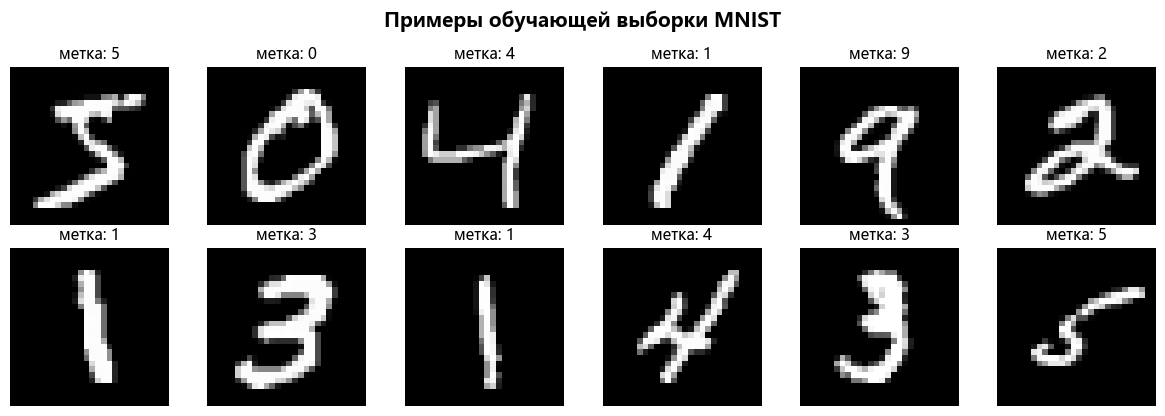

In [5]:
# Просмотр первых картинок
import matplotlib.pyplot as plt
plt.close('all')

fig, axes = plt.subplots(2, 6, figsize=(12, 4.2))
for i, ax in enumerate(axes.ravel()):
    img, label = train_ds[i]
    ax.imshow(img.squeeze(), cmap='gray')
    ax.set_title(f'метка: {label.item()}', fontsize=11)
    ax.axis('off')
plt.suptitle('Примеры обучающей выборки MNIST', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Вопросы для самопроверки:**
1. Зачем нужен `shuffle=True` для обучающего загрузчика? (Чтобы батчи были разнообразными и сеть не подстраивалась под порядок.)
2. Что делает деление на 255? (Приводит пиксели к диапазону 0..1 — так градиентному спуску легче.)
3. Почему у тензора появляется размерность 1 (`unsqueeze(1)`)? (Канал изображения: CNN ждёт вход формы N×1×28×28.)

---
# 🏋️ Часть 3. Обучение (40 мин)

<div style='text-align: center; margin: 20px;'>
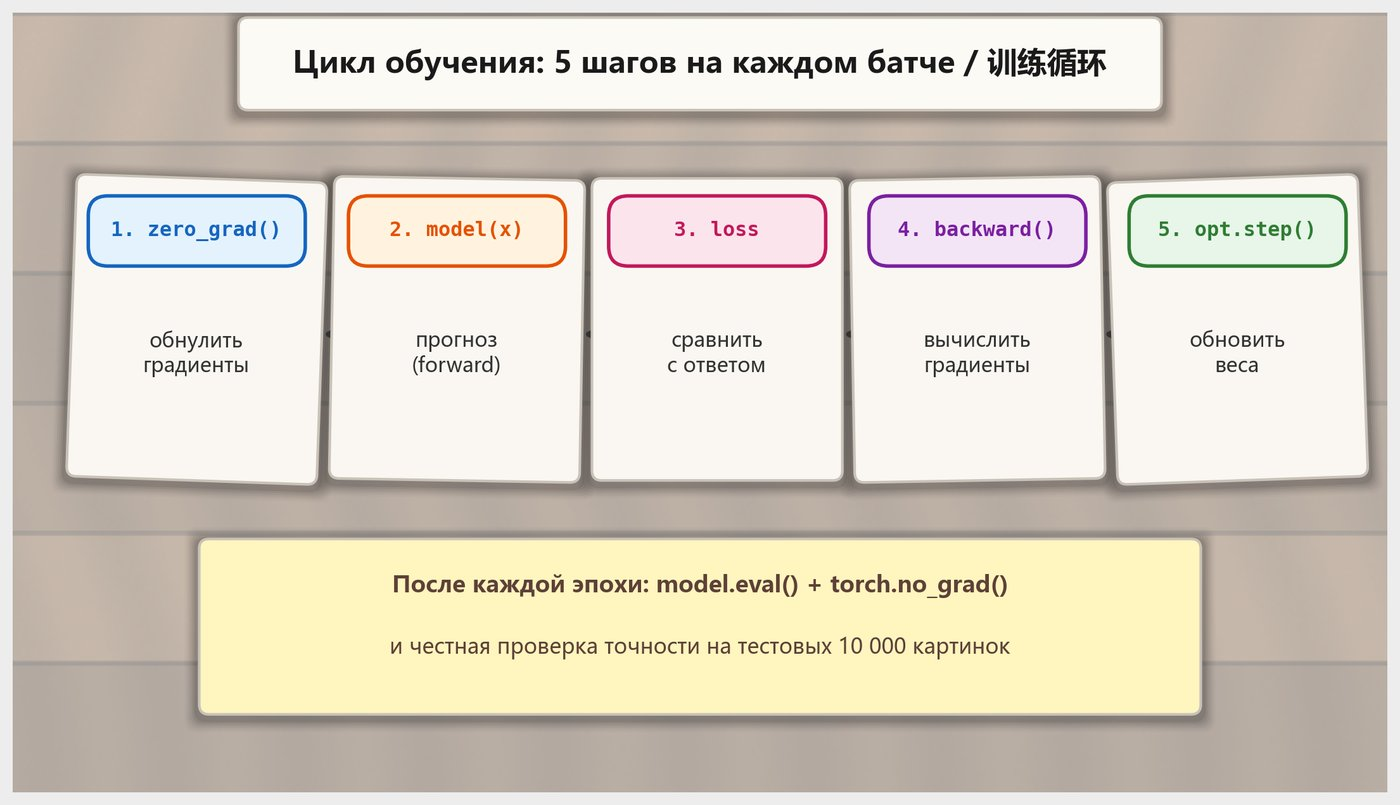
</div>

На обычном ноутбуке без видеокарты одна эпоха занимает примерно от 20 секунд до минуты. Ожидаемая точность — около 98 % уже после первой-второй эпохи.

## 🧠 Подробное описание типичной CNN для MNIST

Перед тем как писать код, разберём по слоям классическую архитектуру, которую
мы сейчас реализуем на PyTorch. Это один из самых распространённых «рецептов»
для небольших изображений:

```
Вход 1×28×28
   │
   ▼
[Conv2d: 1→16, kernel 3×3, padding=1]  → карта признаков 16×28×28
   │
   ▼
[ReLU]                                  → нелинейность, обнуляет негативы
   │
   ▼
[MaxPool2d: 2×2]                        → уменьшает в 2 раза: 16×14×14
   │
   ▼
[Conv2d: 16→32, kernel 3×3, padding=1]  → карта признаков 32×14×14
   │
   ▼
[ReLU]
   │
   ▼
[MaxPool2d: 2×2]                        → 32×7×7
   │
   ▼
[Flatten]                                → вектор длины 32·7·7 = 1568
   │
   ▼
[Linear: 1568→10]                        → логиты для 10 классов-цифр
```

**Пояснение каждой операции:**

- **Conv2d(in, out, kernel, padding)** — двумерная свёртка. У неё есть
  обучаемое ядро размером `out × in × kernel × kernel`. При `padding=1` и
  `kernel=3` размер карты не меняется (28×28 → 28×28), потому что один пиксель
  добавляется с каждой стороны. Каждый фильтр независимо скользит по картинке
  и реагирует на свой признак: первый — на вертикальные края, второй — на
  горизонтальные, третий — на диагонали и т. д.

- **ReLU (Rectified Linear Unit)** — нелинейность `f(x)=max(0, x)`. Без
  неё несколько свёрток подряд математически эквивалентны одной линейной
  операции, и сеть не сможет учить сложные зависимости. ReLU дёшев и работает
  на практике лучше, чем сигмоида или tanh.

- **MaxPool2d(2)** — берёт окно 2×2 без перекрытия и оставляет максимум.
  Карта уменьшается вдвое по каждой стороне: 28×28 → 14×14 → 7×7. Это
  одновременно и сжатие информации, и небольшая инвариантность к сдвигам.

- **Flatten** — превращает многомерный тензор (32, 7, 7) в вектор длины 1568,
  чтобы его можно было подать в полносвязный слой.

- **Linear(1568, 10)** — последний «классификатор»: берёт 1568 признаков и
  выдаёт 10 чисел (логитов) — по одному на каждую цифру. Самое большое число
  и есть предсказание модели.

Почему именно **два** свёрточных блока? Первый блок находит простые признаки
(края, штрихи), второй — их комбинации (петли, пересечения). Для MNIST этого
достаточно: сеть содержит всего ~25 000 параметров и обучается на CPU за
минуту, достигая 98 % точности.


In [6]:
import torch.nn as nn

model = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 10))

loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

total = sum(p.numel() for p in model.parameters())
print('Всего обучаемых параметров:', total)

Всего обучаемых параметров: 20490


## 🔁 Как устроен цикл обучения

Код ниже выглядит как обычный двойной `for`, но за каждой строкой стоит
концепция градиентного спуска. Разберём их по порядку.

**Эпоха (epoch)** — один полный проход модели по всему обучающему набору.
За одну эпоху сеть «видит» каждую картинку ровно один раз. Обычно 3–5 эпох
уже достаточно для MNIST, потому что набор небольшой, а модель простая.

**Батч (mini-batch)** — небольшая порция примеров (у нас 64), которая
подаётся в модель одновременно. На каждом батче:
1. вычисляется прогноз сети `model(x)`;
2. считается функция потерь `loss_fn(pred, y)` — насколько прогноз далёк от
   правильных меток (для классификации используют **CrossEntropyLoss**);
3. `loss.backward()` — обратное распространение ошибки: PyTorch проходит
   граф вычислений назад и складывает частные производные в `.grad` каждого
   тензора-параметра;
4. `opt.step()` — оптимизатор (Adam) делает шаг по вычисленным градиентам и
   обновляет веса: `w -= lr * grad`. Это и есть собственно обучение;
5. `opt.zero_grad()` — **обязательно** обнуляет накопленные градиенты перед
   следующим батчем. Если забыть эту строку, градиенты будут складываться
   от батча к батчу, и шаг станет огромным — обучение «взорвётся».

Почему **`zero_grad()`** вообще нужен? PyTorch накапливает градиенты по
умолчанию — это удобно для RNN и для сложения потерь из нескольких частей,
но в простом цикле обучения мы хотим «чистый» градиент именно текущего
батча, поэтому накопление нужно стирать.

**Mini-batch SGD.** Обновлять веса на каждом батче — это стохастический
градиентный спуск с мини-батчами: он быстрее полного пакетного градиента,
даёт «шумные» шаги (что помогает выбираться из локальных минимумов) и
эффективно использует векторные инструкции CPU/GPU. Adam — это
усовершенствованный SGD с адаптивным шагом для каждого параметра.

**`model.train()` / `model.eval()`.** Перед обучением вызываем
`model.train()` — это включает режим тренировки для слоёв Dropout и
BatchNorm (Dropout «выключает» случайные нейроны, BatchNorm использует
статистики батча). Перед измерением точности на тесте вызываем
`model.eval()` — те же слои переходят в инференс-режим: Dropout отключён,
BatchNorm использует накопленные средние. Это критично для
воспроизводимости результата.

**`torch.no_grad()`.** Контекстный менеджер отключает построение графа
вычислений. На тесте нам не нужны градиенты, поэтому мы их выключаем —
экономия памяти и ускорение в несколько раз.


In [7]:
for epoch in range(3):
    model.train()
    for x, y in train_loader:
        opt.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        opt.step()

    model.eval()
    correct = 0
    with torch.no_grad():
        for x, y in test_loader:
            correct += (model(x).argmax(1) == y).sum().item()
    print(f'Эпоха {epoch + 1}: точность на тесте {correct / len(test_ds):.2%}')

Эпоха 1: точность на тесте 97.97%
Эпоха 2: точность на тесте 98.30%
Эпоха 3: точность на тесте 98.74%


**Разбор строк цикла:**
- `model.train()` / `model.eval()` — переключение режимов (важно для Dropout и BatchNorm);
- `torch.no_grad()` — отключает подсчёт градиентов при проверке: быстрее и экономит память;
- `argmax(1)` — номер класса с наибольшим score;
- точность считаем **на тесте**, которого сеть не видела при обучении.

In [8]:
# Сохранение модели — файл понадобится на Практике 9 (Flask-сервис)
torch.save(model.state_dict(), 'mnist_cnn.pth')
print('Сохранено: mnist_cnn.pth,', os.path.getsize('mnist_cnn.pth'), 'байт')

Сохранено: mnist_cnn.pth, 85037 байт


---
# 🔍 Часть 3.5. Анализ ошибок модели

Общая точность говорит не всё. Чтобы понять, **где модель слаба**, разберём её ошибки тремя способами:

1. **Матрица ошибок (混淆矩阵)** — таблица 10×10: какие цифры с какими путаются;
2. **Примеры неправильных прогнозов** — посмотрим глазами, почему модель ошиблась;
3. **Самые неуверенные прогнозы** — где модель «сомневается» больше всего.

Сначала прогоним модель по всем 10 000 тестовых примеров и сохраним прогнозы и вероятности.

In [9]:
all_preds, all_labels, all_probs = [], [], []

model.eval()
with torch.no_grad():
    for x, y in test_loader:
        logits = model(x)
        all_preds.extend(logits.argmax(1).numpy())
        all_labels.extend(y.numpy())
        all_probs.append(torch.softmax(logits, dim=1))

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = torch.cat(all_probs).numpy()   # (10000, 10)

print(f'Всего примеров: {len(all_preds)}')
print(f'Правильных:     {(all_preds == all_labels).sum()}')
print(f'Ошибок:         {(all_preds != all_labels).sum()}')

Всего примеров: 10000
Правильных:     9874
Ошибок:         126


## 1. Матрица ошибок (Confusion Matrix / 混淆矩阵)

Строка — истинный класс, столбец — предсказанный. На главной диагонали — правильные ответы, вне диагонали — ошибки. Чем темнее клетка вне диагонали, тем чаще модель путает эти две цифры.

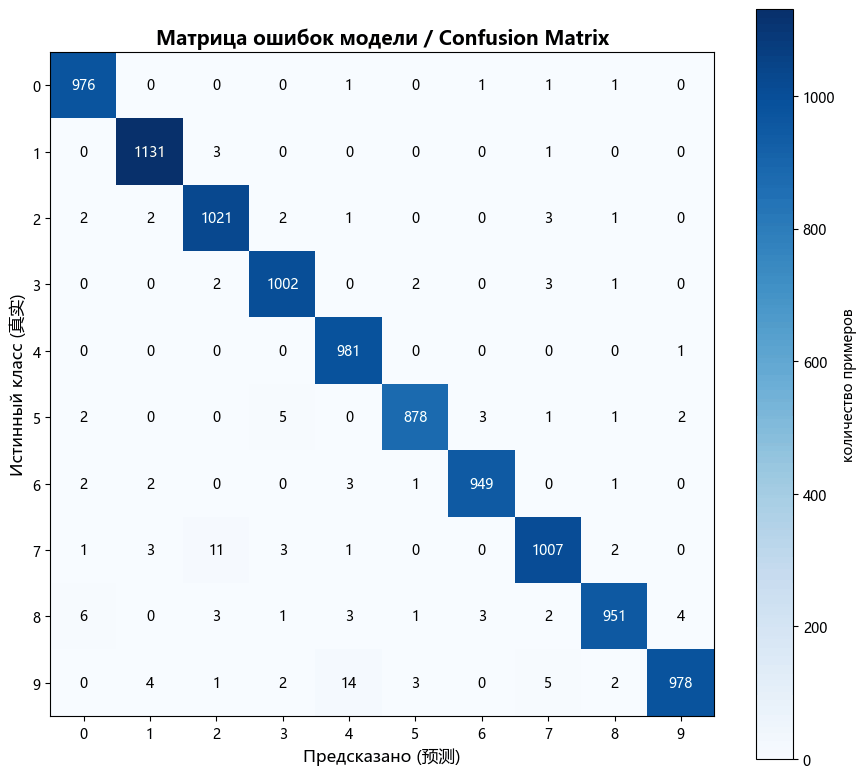


Топ-5 самых частых ошибок:
  цифру 9 назвали 4 — 14 раз
  цифру 7 назвали 2 — 11 раз
  цифру 8 назвали 0 — 6 раз
  цифру 9 назвали 7 — 5 раз
  цифру 5 назвали 3 — 5 раз


In [10]:
import itertools

cm = np.zeros((10, 10), dtype=int)
for true, pred in zip(all_labels, all_preds):
    cm[true, pred] += 1

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap='Blues', interpolation='nearest')
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(range(10)); ax.set_yticklabels(range(10))
ax.set_xlabel('Предсказано (预测)', fontsize=12)
ax.set_ylabel('Истинный класс (真实)', fontsize=12)
ax.set_title('Матрица ошибок модели / Confusion Matrix', fontsize=14, fontweight='bold')

threshold = cm.max() / 2
for i, j in itertools.product(range(10), range(10)):
    ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=10,
            color='white' if cm[i, j] > threshold else 'black')

plt.colorbar(im, label='количество примеров')
plt.tight_layout()
plt.show()

print('\nТоп-5 самых частых ошибок:')
errors = [(cm[i, j], i, j) for i in range(10) for j in range(10) if i != j]
errors.sort(reverse=True)
for count, true, pred in errors[:5]:
    print(f'  цифру {true} назвали {pred} — {count} раз')

## 2. Примеры неправильно распознанных цифр

Посмотрим глазами на 24 ошибки: в чём модель «обманулась»? Часто это размазанные, кривые или необычно написанные цифры — те же, с которыми засомневался бы человек.

Всего ошибок: 126. Показываем первые 24.


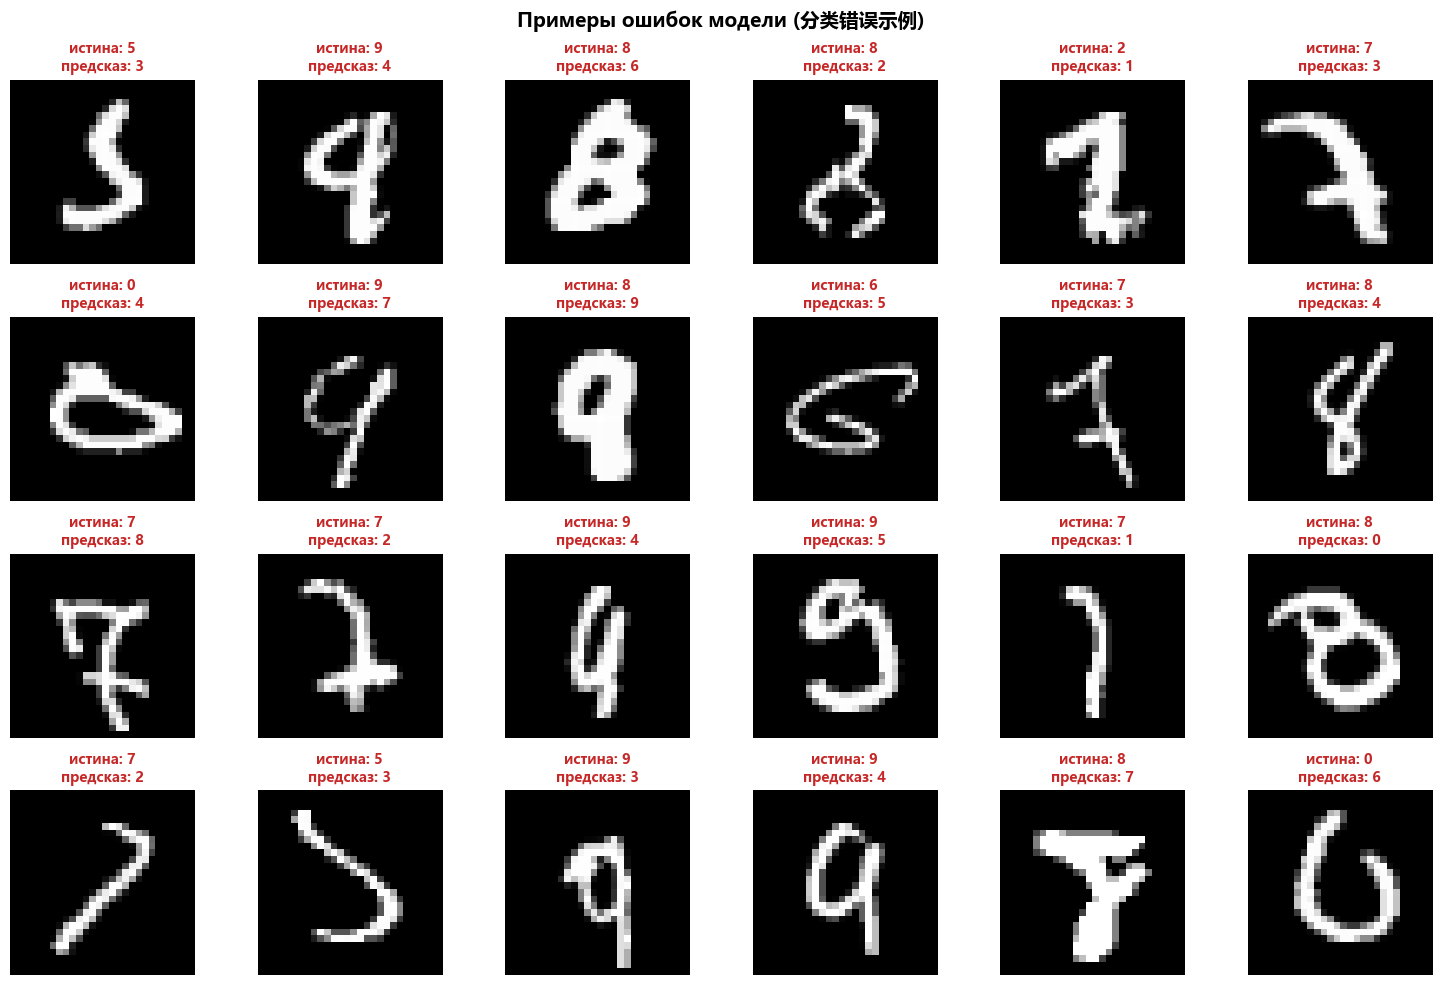

In [11]:
wrong_idx = np.where(all_preds != all_labels)[0]
print(f'Всего ошибок: {len(wrong_idx)}. Показываем первые 24.')

fig, axes = plt.subplots(4, 6, figsize=(15, 10))
for i, ax in enumerate(axes.ravel()):
    if i < len(wrong_idx):
        idx = wrong_idx[i]
        img, true_label = test_ds[int(idx)]
        ax.imshow(img.squeeze(), cmap='gray')
        ax.set_title(f'истина: {true_label.item()}\nпредсказ: {all_preds[idx]}',
                     color='#C62828', fontsize=10, fontweight='bold')
    ax.axis('off')

plt.suptitle('Примеры ошибок модели (分类错误示例)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Самые неуверенные прогнозы

Для каждого примера смотрим на **вероятность правильного класса**. Если она маленькая (например, 30 %) — модель почти не уверена в ответе. Такие примеры стоит добавить в обучающую выборку или показать эксперту.

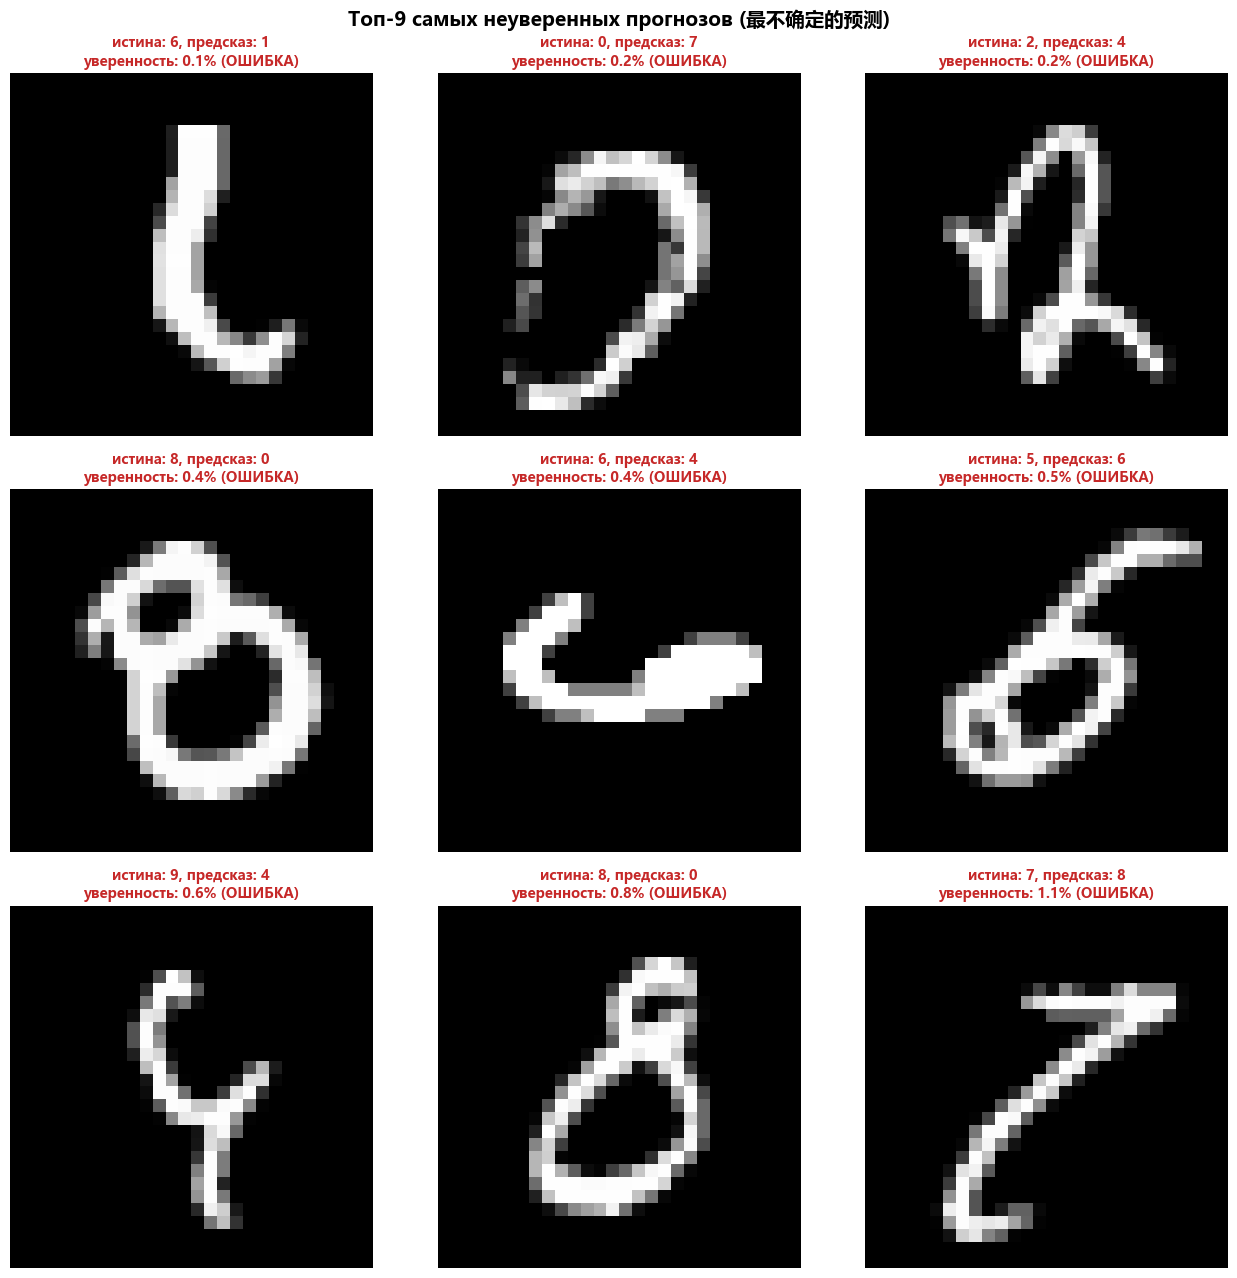

Средняя уверенность модели: 97.9%
Примеров с уверенностью < 50%: 142
Примеров с уверенностью < 10%: 42


In [12]:
correct_probs = all_probs[np.arange(len(all_labels)), all_labels]
sorted_idx = np.argsort(correct_probs)   # сначала самые неуверенные

fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for i, ax in enumerate(axes.ravel()):
    idx = int(sorted_idx[i])
    img, true_label = test_ds[idx]
    pred_label = all_preds[idx]
    conf = correct_probs[idx]
    ax.imshow(img.squeeze(), cmap='gray')
    is_wrong = pred_label != true_label.item()
    color = '#C62828' if is_wrong else '#2E7D32'
    status = 'ОШИБКА' if is_wrong else 'верно'
    ax.set_title(f'истина: {true_label.item()}, предсказ: {pred_label}\n'
                 f'уверенность: {conf:.1%} ({status})',
                 fontsize=10, fontweight='bold', color=color)
    ax.axis('off')

plt.suptitle('Топ-9 самых неуверенных прогнозов (最不确定的预测)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Средняя уверенность модели: {correct_probs.mean():.1%}')
print(f'Примеров с уверенностью < 50%: {(correct_probs < 0.5).sum()}')
print(f'Примеров с уверенностью < 10%: {(correct_probs < 0.1).sum()}')

**Что обсудить:**
1. Какие пары цифр путаются чаще всего? (Обычно 4↔9, 3↔8, 2↔7.)
2. Глядя на примеры ошибок — в чём модель «обманулась»? (наклон, разрыв, стиль написания)
3. Совпадают ли самые неуверенные прогнозы с ошибками, или модель иногда угадывает верно «наугад»?
4. Как улучшить модель на этих трудных примерах? (больше данных, аугментация, другая архитектура)

---
# 🧪 Часть 4. Эксперименты (30 мин)

<div style='text-align: center; margin: 20px;'>
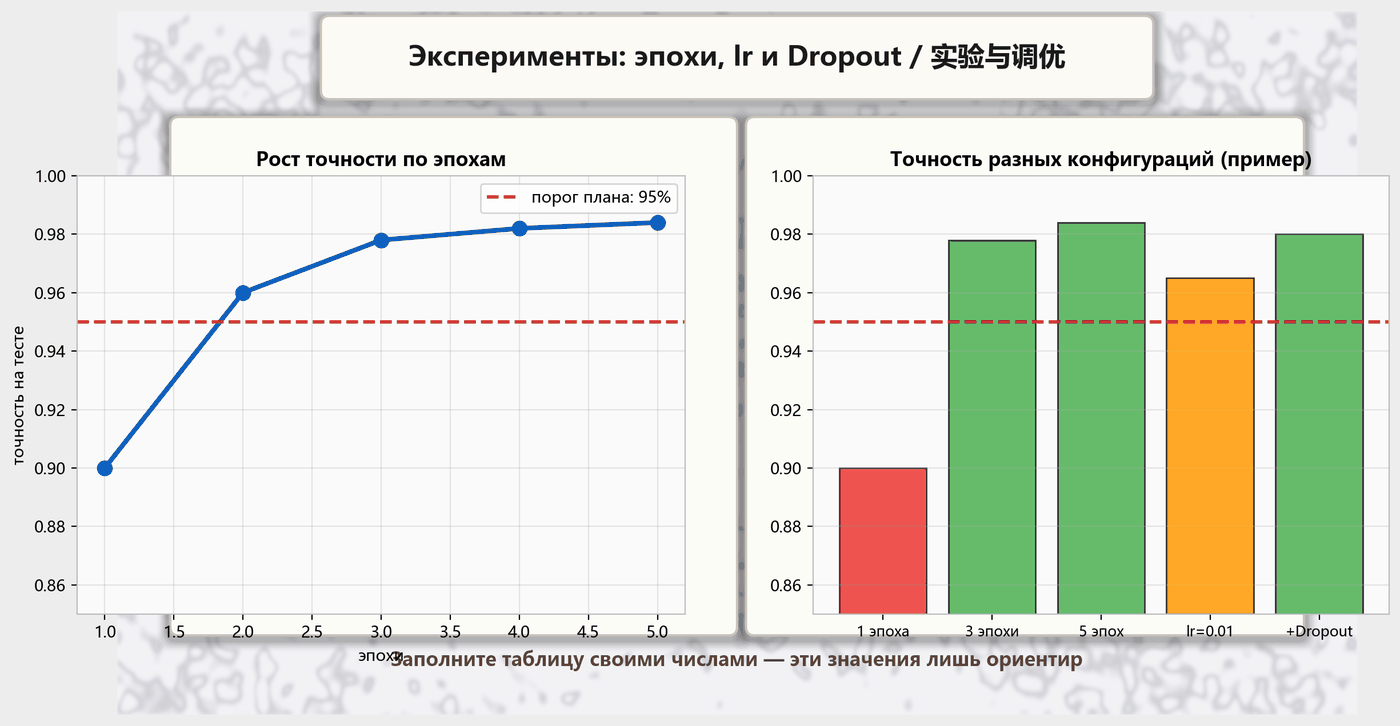
</div>

Задания плана:
1. `range(1)`, `range(3)`, `range(5)` — как растёт точность;
2. `lr=0.01` вместо `0.001`;
3. добавить `nn.Dropout(0.25)` перед последним `nn.Linear`;
4. заполнить таблицу: параметр → точность → вывод.

## ⚙️ Hyperparameter tuning — настройка гиперпараметров

После того как базовая модель работает, начинается самое интересное:
поиск лучшей конфигурации. **Hyperparameter tuning** — это процесс
систематического перебора гиперпараметров с целью максимизировать
качество модели на отложенной выборке (в нашем случае — на 10 000
тестовых картинках MNIST).

**Какие гиперпараметры будем варьировать:**
- **Число эпох** — 1, 3, 5. Покажет, как быстро сходится модель и где
  начинается переобучение.
- **Learning rate (lr)** — 0.001 (по умолчанию у Adam) против 0.01. Слишком
  маленький lr — модель учится медленно; слишком большой — не сходится
  или расходится.
- **Dropout** — дополнительный слой `nn.Dropout(0.25)` перед
  классификатором: случайно обнуляет четверть признаков на каждом шаге
  обучения. Это регуляризация: сеть не может «зазубрить» отдельные пиксели
  и учится опираться на разные признаки.

**Какие метрики смотреть:**
- **Loss (функция потерь)** — как сильно ошибается модель на обучении и
  на тесте. Если train loss падает, а test loss растёт — это верный признак
  **переобучения**: модель запомнила обучающие примеры, но не обобщает.
- **Accuracy (точность)** — доля правильных ответов. На MNIST базовая
  планка — 95 %, хорошая модель — 98–99 %.
- **Confusion matrix** — какие пары цифр путаются (4↔9, 3↔8, 2↔7).
  Помогает понять, где модель слаба и какие данные augment.
- **Confidence правильного класса** — насколько модель уверена там, где
  она права. Низкая уверенность = «повезло», примеры на грани ошибки.

**Как делать выводы.** В таблице ниже будут три колонки: конфигурация,
точность и ваши выводы. После экспериментов ответьте на вопросы:
1. Между какими эпохами точность растёт быстрее всего?
2. Уменьшается ли прирост точности с каждой следующей эпохой?
3. Помог ли lr=0.01 или, наоборот, навредил?
4. Снизил ли Dropout переобучение (видно по разрыву train/test loss)?


In [13]:
def train_eval(epochs=3, lr=1e-3, dropout=False):
    """Обучает сеть с заданными параметрами и возвращает точность на тесте."""
    layers = [
        nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
    ]
    if dropout:
        layers.append(nn.Dropout(0.25))
    layers.append(nn.Linear(32 * 7 * 7, 10))
    net = nn.Sequential(*layers)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)

    for _ in range(epochs):
        net.train()
        for x, y in train_loader:
            optimizer.zero_grad()
            loss = criterion(net(x), y)
            loss.backward()
            optimizer.step()

    net.eval()
    correct = 0
    with torch.no_grad():
        for x, y in test_loader:
            correct += (net(x).argmax(1) == y).sum().item()
    return correct / len(test_ds)

print('Функция готова. Запускайте конфигурации ниже (каждая — до нескольких минут на CPU).')

Функция готова. Запускайте конфигурации ниже (каждая — до нескольких минут на CPU).


In [ ]:
rows = []
configs = [
    {'название': '1 эпоха, lr=0.001',       'epochs': 1, 'lr': 1e-3, 'dropout': False},
    {'название': '3 эпохи, lr=0.001',       'epochs': 3, 'lr': 1e-3, 'dropout': False},
    {'название': '5 эпох, lr=0.001',        'epochs': 5, 'lr': 1e-3, 'dropout': False},
    {'название': '3 эпохи, lr=0.01',        'epochs': 3, 'lr': 1e-2, 'dropout': False},
    {'название': '3 эпохи, lr=0.001, Drop', 'epochs': 3, 'lr': 1e-3, 'dropout': True},
]

for i, cfg in enumerate(configs, 1):
    cfg = dict(cfg)              # чтобы не портить исходный список
    name = cfg.pop('название')
    print(f'[{i}/{len(configs)}] {name} ...')
    acc = train_eval(**cfg)
    rows.append({'Конфигурация': name, 'Точность': round(acc, 4)})
    print(f'    точность = {acc:.2%}')
    pd.DataFrame(rows).to_csv('experiments_p6.csv', index=False)   # сохраняем после каждой

table = pd.DataFrame(rows)
display(table)
print('Сохранено: experiments_p6.csv')

[1/5] 1 эпоха, lr=0.001 ...


**Выводы по экспериментам (допишите своими словами):**
1. Точность растёт быстрее всего между ___ и ___ эпохой, затем прирост почти исчезает.
2. При `lr=0.01` точность ___ , потому что ___ .
3. Dropout изменил точность на ___ ; он полезен, когда ___ .

---
# 📝 Часть 5. Сохранение модели и вывод (15 мин)

## Ожидаемый результат практики
- [x] файл **`mnist_cnn.pth`** рядом с тетрадью (нужен на Практике 8);
- [x] скриншот или таблица с точностью **не ниже 95 %**;
- [x] таблица экспериментов `experiments_p6.csv`;
- [x] матрица ошибок и примеры неправильных прогнозов (Часть 3.5);
- [x] письменный вывод на 5–6 предложений.

**Шаблон вывода:**
> В практике я обучил(а) свёрточную сеть на MNIST. После первой эпохи точность была …, после третьей — …, что выше требуемых 95 %. Увеличение числа эпох с 3 до 5 дало прирост …, потому что … . Повышение скорости обучения до 0.01 привело к …, что согласуется с идеей «слишком большого шага в тумане». Dropout изменил результат на … и полезен как защита от переобучения. Матрица ошибок показала, что чаще всего путаются цифры … и …. Файл mnist_cnn.pth я сохранил(а) для Практики 8.

## Проверка модели на своих рисунках (дополнительно)
Нарисуйте цифру в Paint (толстая кисть). Ячейка сама определит, белая цифра на чёрном или наоборот:

In [ ]:
from PIL import Image

path = 'my_digit.png'
if os.path.exists(path):
    arr = np.array(Image.open(path).convert('L').resize((28, 28)), dtype='float32') / 255.0
    if arr.mean() > 0.5:          # в MNIST белая цифра на чёрном; инвертируем при необходимости
        arr = 1.0 - arr
    x = torch.from_numpy(arr).unsqueeze(0).unsqueeze(0)   # (1, 1, 28, 28)
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)
        digit = int(probs.argmax(1).item())
    print(f'Модель увидела цифру {digit} (уверенность {probs[0, digit]:.1%})')
else:
    print('Файл my_digit.png не найден — пропустите ячейку или нарисуйте цифру в Paint.')

---
## ❓ Вопросы для устной защиты

1. Почему для MNIST нужна свёрточная сеть, а не полносвязная?
2. Что делает `nn.MaxPool2d(2)` и зачем он нужен?
3. Зачем вызывать `model.eval()` и `torch.no_grad()` при проверке точности?
4. Почему точность измеряют на тестовой выборке, а не на обучающей?
5. Что произойдёт при `lr=1.0`? Объясните через аналогию с шагом в тумане.
6. Что сохраняется в файле `mnist_cnn.pth` и зачем он нужен на Практике 8?
7. Что показывает матрица ошибок и какие пары цифр путаются чаще всего?

---
## 🆘 Типичные ошибки

| Ошибка | Причина | Решение |
|--------|---------|---------|
| `RuntimeError: Dataset not found` (torchvision) | нет папки `data/MNIST/raw` | наш загрузчик скачивает с зеркал Huawei/Tsinghua либо копируйте с флешки |
| Зависание при `download=True` | серверы MNIST недоступны в Китае | не использовать download=True |
| `RuntimeError: expected 4-dimensional input` | тензор без канала | `unsqueeze(1)` даёт форму (n, 1, 28, 28) |
| Точность скачет и не растёт | слишком большой `lr` | верните `lr=1e-3` |
| Точность на тесте ниже обучающей на 10 %+ | переобучение | Dropout, меньше эпох |
| `my_digit.png` распознаётся неверно | в Paint чёрная цифра на белом | ячейка сама инвертирует по среднему значению |
| Warning про KMeans/MKL | особенность Windows + MKL | `os.environ['OMP_NUM_THREADS']='1'` в первой ячейке |

---
## 📚 Словарь терминов

| Русский | 中文 | English |
|---------|------|---------|
| Свёрточная сеть | 卷积神经网络 | CNN |
| Свёртка | 卷积 | Convolution |
| Пулинг | 池化 | Pooling |
| Карта признаков | 特征图 | Feature map |
| Эпоха | 轮次 | Epoch |
| Батч | 批次 | Batch |
| Скорость обучения | 学习率 | Learning rate |
| Функция потерь | 损失函数 | Loss function |
| Точность | 准确率 | Accuracy |
| Переобучение | 过拟合 | Overfitting |
| Матрица ошибок | 混淆矩阵 | Confusion matrix |
| Состояние модели | 模型状态 | State dict |

---
## 🏠 Домашнее задание

1. Дообучите сохранённую модель ещё 2 эпохи, загрузив веса: `model.load_state_dict(torch.load('mnist_cnn.pth'))`. Изменилась ли точность?
2. Нарисуйте в Paint три цифры и проверьте прогнозы (ячейка выше). Опишите, какие цифры путаются и почему.
3. Постройте матрицу ошибок для модели с `Dropout(0.25)` и сравните с базовой: каких путаниц стало меньше?
4. Подготовьте один слайд к Практике 8: архитектура сети, итоговая точность, таблица экспериментов.

<center><i>Преподаватель: _______________ · Оценка: _____ / 100</i></center>

## 🏁 Итоги практики

За 120 минут мы прошли полный цикл построения нейросети для распознавания
цифр: от загрузки данных до экспериментов с гиперпараметрами. Главные выводы:

1. **CNN подходит для изображений лучше полносвязной сети.** Свёртка скользит
   фильтром по картинке и находит паттерны (края, штрихи, петли) вне
   зависимости от их положения, а пулинг сжимает карту признаков, оставляя
   главное. Для 28×28-картинки MNIST наша маленькая CNN содержит всего
   ~25 000 параметров — против миллионов у эквивалентной MLP — и учится
   за минуту на обычном ноутбуке.

2. **Архитектура из двух свёрточных блоков (Conv → ReLU → MaxPool) ×2 +
   Flatten + Linear** даёт точность 98 % уже после 2–3 эпох. Дальнейшее
   усложнение сети на MNIST даёт diminishing returns.

3. **Цикл обучения** — это пять повторяющихся шагов: `zero_grad → forward →
   loss → backward → step`. Понимание каждого из них важнее, чем сам код:
   например, забытый `zero_grad()` ломает обучение, а забытый `model.eval()`
   искажает метрики на тесте.

4. **Подбор гиперпараметров** — это не чёрная магия, а систематический
   перебор. На MNIST lr=0.001 с Adam работает стабильно; lr=0.01 часто
   слишком агрессивен; Dropout помогает против переобучения, но на маленькой
   модели разница может быть незаметна.

5. **Анализ ошибок** информативнее одной цифры точности. Confusion matrix
   показывает, какие пары цифр путаются (4↔9, 3↔8). Глядя на 24 неправильных
   примера, мы видим, что сеть ошибается именно там, где ошибся бы и человек:
   размазанные «четвёрки», «тройки» с лишним хвостиком и т. д.

Готовая модель сохранена в файл **`mnist_cnn.pth`** — на Практике 8 мы
развернём её в веб-сервис на Flask и научим приложение принимать картинку
из браузера и возвращать предсказание цифры.
